# Heart Disease Prediction — Part 4: CardioAgent, the Intelligent Agent

Parts 1–3 built the pieces. **Part 4 puts them together into an agent** that a patient (or nurse) could actually use:

```
  patient's checkup values
            │
            ▼
  ┌──────────────────────────────────────────────────────────────────┐
  │  CardioAgent                                                     │
  │   1. PERCEIVE  check the input; decide quick or full assessment  │
  │   2. THINK     risk (MLP) · profile (k-means) · main factors     │
  │                what-if · PLAN: cheapest changes to lower risk    │
  │   3. ACT       write a report a person can understand            │
  └──────────────────────────────────────────────────────────────────┘
            │
            ▼
  "Risk 88% (HIGH). Profile: smokers & drinkers.
   Plan: lower BP to 125/80, cholesterol to normal, become active → 36%."
```

| Step | What we do | Course link |
|---|---|---|
| 1 | What is an agent? PEAS description | Lecture 11, Lab 8 |
| 2 | Build the agent (reuses Parts 1–3) | — |
| 3 | **Safety check:** can we trust the model's what-if answers? | — |
| 4 | The knowledge base — rules that keep the advice safe | Neuro-symbolic AI |
| 5 | Perceive: validate the input, choose a mode | Lecture 11 |
| 6 | Think: risk, profile, factors, what-if | Parts 1–3 |
| 7 | Plan: **uniform-cost search** for the easiest set of changes | Lecture 12 |
| 8 | Act: full reports for example patients | — |
| 9 | Evaluate the agent on 1,000 test patients | Lecture 6 |

> The agent's code lives in **`cardio_agent.py`** (≈ 300 lines, heavily commented). This notebook explains and tests it. Runtime ≈ 30 seconds.

## Step 1 — What is an agent?

**Lecture 11:** an **agent** is anything that **perceives** its environment through **sensors** and **acts** on it through **actuators**.
A **rational** agent chooses the action expected to do best on its **performance measure**.

```
            ┌───────────── environment ─────────────┐
            │  patient / nurse with checkup values  │
            └──────┬────────────────────────▲───────┘
         sensors   │ input                  │ report   actuators
                   ▼                        │
            ┌──────────────────────────────────────┐
            │              AGENT                   │
            │  percepts → [ agent program ] → action│
            └──────────────────────────────────────┘
```

### PEAS description of CardioAgent (Lecture 11, Lab 8)

| PEAS | CardioAgent |
|---|---|
| **P**erformance measure | Catch ≥ 80% of patients with heart disease (recall); give advice that is **safe** (never recommends an unhealthy change) and **easy** (lowest effort); be understandable |
| **E**nvironment | Patients' routine checkup records: age, sex, height, weight, blood pressure, cholesterol, glucose, smoking, alcohol, activity |
| **A**ctuators | A written report: risk level, patient profile, main factors, what-if table, a lifestyle plan, guideline advice, disclaimer |
| **S**ensors | The input form / record with the 11 values (or just 3 for a quick screening) |

### Which kind of agent is it? (Lecture 11 agent types)

| Agent type | Does CardioAgent do this? |
|---|---|
| Simple reflex (if–then rules) | Partly: input checks and guideline advice are rules |
| Model-based (keeps a model of the world) | ✔ the trained MLPs are its model of how checkup values relate to disease |
| **Goal-based** (searches for actions that reach a goal) | ✔ goal: bring the risk **below the follow-up threshold** |
| **Utility-based** (prefers the *best* way to reach the goal) | ✔ among plans that reach the goal, choose the one with **lowest effort** |
| Learning agent | The learning element (training, the GA in Part 2) runs **offline**; the agent uses what was learned |

So CardioAgent is a **utility-based agent** built on learned models.

**Environment properties (Lecture 11):** fully observable (we see all inputs), **episodic** (each patient is independent),
**static** (nothing changes while it thinks), **single-agent**.

## Step 2 — Build the agent

`CardioAgent()` assembles the parts from earlier notebooks:

| Component | Comes from | Used for |
|---|---|---|
| **Full model**: MLP (16, 8), all 10 features | Part 1 design | Full assessment, what-if, planning |
| **Quick model**: MLP (32, 16), 3 features | Part 2 GA (`results/ga_best_design.json`) | Quick screening when only age, BP, cholesterol are known |
| **Patient profiles**: 4 k-means centres | Part 3 (`results/patient_profiles.json`) | Explaining the patient's group |
| **Thresholds** | chosen on validation, recall ≥ 80% (same rule as Parts 1–2) | Deciding LOW vs. ELEVATED / HIGH |

The two MLPs are retrained when the agent starts (≈ 2 seconds, same seed → same models every time).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

from cardio_utils import load_clean_data, split_and_scale
from cardio_agent import CardioAgent, MEASURABLE_ACTIONS, GUIDELINE_ONLY

sns.set_theme(style="whitegrid")

agent = CardioAgent()
data = split_and_scale(load_clean_data())

print("Quick model uses:", agent.quick_features)
print("Follow-up thresholds → full:", agent.full_threshold, "| quick:", agent.quick_threshold)

Quick model uses: ['ap_hi', 'cholesterol', 'age_years']
Follow-up thresholds → full: 0.41 | quick: 0.36


## Step 3 — Safety check: can we trust the model's what-if answers?

The agent's advice depends on asking the model *"what if this patient made a healthy change?"*.
Before trusting that, we **test it**: for every validation patient who could make a change, apply the change and see whether the
model's risk goes **down** (sensible) or **up** (wrong).

The changes tested, each in the medically **healthy** direction:

In [2]:
X_val = data["X_val"].copy()

def apply_change(X, change):
    # Return (changed copy of X, mask of patients the change applies to).
    A = X.copy()
    if change == "Lower BP by 10/5":
        m = A["ap_hi"] > 120; A.loc[m, "ap_hi"] -= 10; A.loc[m, "ap_lo"] = np.maximum(A.loc[m, "ap_lo"] - 5, 60)
    elif change == "Cholesterol down 1 level":
        m = A["cholesterol"] > 1; A.loc[m, "cholesterol"] -= 1
    elif change == "Become active":
        m = A["active"] == 0; A.loc[m, "active"] = 1
    elif change == "BMI down 2":
        m = A["bmi"] > 25; A.loc[m, "bmi"] -= 2
    elif change == "Quit smoking":
        m = A["smoke"] == 1; A.loc[m, "smoke"] = 0
    elif change == "Quit alcohol":
        m = A["alco"] == 1; A.loc[m, "alco"] = 0
    elif change == "Glucose down 1 level":
        m = A["gluc"] > 1; A.loc[m, "gluc"] -= 1
    return A, m

before = agent.full_model.predict_proba(agent.scaler.transform(X_val))[:, 1]
rows = []
for change in ["Lower BP by 10/5", "Cholesterol down 1 level", "Become active", "BMI down 2",
               "Quit smoking", "Quit alcohol", "Glucose down 1 level"]:
    A, m = apply_change(X_val, change)
    after = agent.full_model.predict_proba(agent.scaler.transform(A))[:, 1]
    delta = (after - before)[m.values]
    rows.append({"healthy change": change, "patients": int(m.sum()),
                 "average risk change": delta.mean(),
                 "% where model says risk goes UP": (delta > 0.005).mean() * 100})
safety = pd.DataFrame(rows).set_index("healthy change")
safety.round(3)

,patients,average risk change,% where model says risk goes UP
healthy change,,,
Lower BP by 10/5,4217,-0.127,1.399
Cholesterol down 1 level,2568,-0.077,10.864
Become active,2010,-0.048,11.095
BMI down 2,6269,-0.010,5.519
Quit smoking,894,0.012,55.145
Quit alcohol,555,0.041,70.631
Glucose down 1 level,1576,0.021,69.099


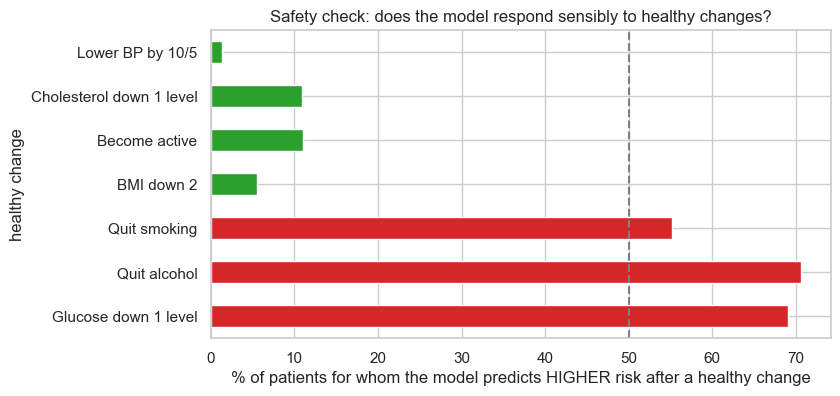

In [3]:
colours = ["tab:red" if v > 50 else "tab:green" for v in safety["% where model says risk goes UP"]]
safety["% where model says risk goes UP"].plot(kind="barh", color=colours, figsize=(8, 4))
plt.axvline(50, color="grey", linestyle="--")
plt.xlabel("% of patients for whom the model predicts HIGHER risk after a healthy change")
plt.title("Safety check: does the model respond sensibly to healthy changes?")
plt.gca().invert_yaxis()
plt.show()

### ⚠ An important finding

| Healthy change | Model's answer |
|---|---|
| Lower blood pressure, lower cholesterol, become active, lose weight | Risk goes **down** for almost everyone ✔ |
| **Quit smoking, quit alcohol, lower glucose** | Risk goes **UP** for most patients ✘ |

Medically, quitting smoking clearly lowers heart risk. So why does the model disagree?
The model learns **associations in this dataset, not causes**:
- smoking and alcohol are **self-reported**, and the smokers here are mostly **younger men** (Part 3, "smokers & drinkers" profile);
- glucose rises together with cholesterol, so once cholesterol is known, glucose adds confusing information.

**If the agent trusted the model blindly, it would effectively tell patients to keep smoking.**
That is exactly why an agent needs more than a model.

## Step 4 — The knowledge base: rules that keep the advice safe

CardioAgent combines the **learned model** with a small **symbolic knowledge base** (hand-written medical rules).
Combining learning with rules is called **neuro-symbolic AI** — one of the areas the project guidelines encourage.

```
           LEARNED (neural)                         SYMBOLIC (rules)
   ┌───────────────────────────┐          ┌────────────────────────────────────┐
   │ MLP: how checkup values   │          │ • valid input ranges               │
   │ relate to heart disease   │   +      │ • which changes are HEALTHY        │
   │                           │          │ • which model answers to IGNORE    │
   └─────────────┬─────────────┘          │   (smoking, alcohol, glucose)      │
                 │                        │ • never show a healthy change as   │
                 │                        │   harmful                          │
                 │                        └─────────────────┬──────────────────┘
                 └──────────────┬───────────────────────────┘
                                ▼
                     safe, explainable advice
```

The rules, from `cardio_agent.py`:

In [4]:
print("Changes the PLANNER may use (model agrees they lower risk; effort cost in brackets):")
for name, a in MEASURABLE_ACTIONS.items():
    print(f"  • {a['label']:<52} [effort {a['cost']}]")

print("\nChanges recommended from GUIDELINES only (model's number is ignored for these):")
for key, msg in GUIDELINE_ONLY.items():
    print(f"  • {msg}")

Changes the PLANNER may use (model agrees they lower risk; effort cost in brackets):
  • Lower blood pressure by 10/5 mmHg (toward 120/80)    [effort 2]
  • Lower cholesterol by one level                       [effort 2]
  • Lose weight (BMI −2, toward 25)                      [effort 2]
  • Become physically active                             [effort 1]

Changes recommended from GUIDELINES only (model's number is ignored for these):
  • Stop smoking
  • Reduce or stop alcohol
  • Bring blood sugar (glucose) to normal


- The **planner** only searches over the four changes in the first list — each is healthy *and* the model handles it sensibly (Step 3).
- Smoking, alcohol and glucose are still **recommended**, but from medical guidelines, with an honest note that the dataset can't measure their effect.
- Even for allowed changes, the model can occasionally misbehave for an individual patient (≈ 1–11% in Step 3).
  Rule: a healthy change is **never displayed as increasing risk** — the agent shows "no change" instead.

The **effort costs** are our own judgement (becoming active is easier than losing weight). They are part of the knowledge base, and you can change them.

## Step 5 — PERCEIVE: check the input and choose a mode

Before thinking, the agent checks what it received:

```
 all 11 values given?  ──yes──▶  FULL assessment (risk + profile + what-if + plan)
        │ no
        ▼
 age + BP + cholesterol given? ──yes──▶  QUICK screening (GA model, risk only)
        │ no
        ▼
 refuse: "missing required values"

 any value outside its valid range?  ──▶  refuse, and say which value is wrong
 age outside 29–65 (training data)?  ──▶  continue, but warn: less reliable
```

Choosing the model based on **what information is available** is a simple but real piece of agent behaviour —
and it's where the GA result from Part 2 earns its place: **3 values are enough for a quick screening.**

In [5]:
examples = {
    "complete record":   dict(age_years=50, is_male=1, height_cm=175, weight_kg=90, ap_hi=135, ap_lo=85,
                              cholesterol=2, gluc=1, smoke=1, alco=0, active=0),
    "only 3 values":     dict(age_years=58, ap_hi=150, cholesterol=2),
    "impossible values": dict(age_years=50, is_male=1, height_cm=175, weight_kg=90, ap_hi=80, ap_lo=120,
                              cholesterol=4, gluc=1, smoke=1, alco=0, active=0),
    "too young":         dict(age_years=22, ap_hi=120, cholesterol=1),
    "missing BP":        dict(age_years=50, cholesterol=1),
}
for name, patient in examples.items():
    mode, errors, warnings = agent.perceive(patient)
    print(f"{name:<18} → mode: {mode}")
    for e in errors:   print(f"{'':<21}✘ {e}")
    for w in warnings: print(f"{'':<21}⚠ {w}")

complete record    → mode: full
only 3 values      → mode: quick
                     ⚠ Only age, blood pressure and cholesterol given: running a QUICK screening. Add the other values for a full assessment with advice.
impossible values  → mode: full
                     ✘ cholesterol = 4 must be one of [1, 2, 3]
                     ✘ Systolic blood pressure (ap_hi) must be higher than diastolic (ap_lo)
too young          → mode: quick
                     ⚠ Only age, blood pressure and cholesterol given: running a QUICK screening. Add the other values for a full assessment with advice.
                     ⚠ Age 22 is outside the ages in the training data (29–65); the estimate is less reliable.
missing BP         → mode: None
                     ✘ Missing required values: ['ap_hi']


## Step 6 — THINK: risk, profile, factors, what-if

For a full assessment the agent computes four things:

| Output | How |
|---|---|
| **Risk** | Full MLP → probability; compared with the threshold → LOW (below threshold), ELEVATED, or HIGH (≥ 70%) |
| **Profile** | Scale the patient, find the **nearest k-means centre** (Part 3) |
| **Main factors** | Simple rules: BP ≥ 130, cholesterol above normal, BMI ≥ 25, age ≥ 55 |
| **What-if** | Make each allowed change **in full** (e.g. BP all the way to 120/80), re-run the model, compare |

In [6]:
patient = examples["complete record"]
r = agent.assess(patient)

print(f"Risk: {r['risk']:.0%}  →  level {r['level']} (threshold {r['threshold']:.0%})")
print(f"Profile: {r['profile']['name']} (group disease rate {r['profile']['disease_rate']:.0%})")
print("Main factors:")
for f in r["factors"]:
    print("  •", f)
print("What-if:")
for text, new_risk, corrected in r["what_if"]:
    print(f"  {text:<50} {r['risk']:.0%} → {new_risk:.0%}" + ("  (corrected by knowledge base)" if corrected else ""))

Risk: 88%  →  level HIGH (threshold 41%)
Profile: Smokers & drinkers (group disease rate 46%)
Main factors:
  • blood pressure 135/85 (low-risk group average 117/77)
  • cholesterol level 2 (normal = 1)
  • BMI 29.4 (overweight range 25–30)
What-if:
  Lower blood pressure from 135/85 to 120/80         88% → 61%
  Lower cholesterol from level 2 to 1 (normal)       88% → 73%
  Become physically active                           88% → 82%
  Lose about 13 kg (BMI 29.4 → 25.0)                 88% → 86%


Notice: the patient is in the **"smokers & drinkers"** group (46% disease rate), but their personal risk is much higher (88%)
because of their blood pressure and cholesterol. The **profile** gives context; the **MLP** gives the personal number.

## Step 7 — PLAN: search for the easiest set of changes (Lecture 12)

The what-if table looks at one change at a time. But the real question is:

> *"What is the **easiest combination** of changes that brings my risk below the follow-up threshold?"*

That is a **search problem** (Lectures 11–12). We define it exactly as in class:

| Search element | CardioAgent |
|---|---|
| **State** | how many steps of each change have been applied: `(BP steps, cholesterol steps, weight steps, active)` |
| **Initial state** | `(0, 0, 0, 0)` — no changes |
| **Actions** | one more step of a change: BP −10/5 mmHg · cholesterol −1 level · BMI −2 · become active (only if still applicable) |
| **Path cost** | sum of effort costs (BP 2, cholesterol 2, weight 2, active 1) |
| **Goal test** | full-model risk **< threshold** |

```
                         (0,0,0,0)  risk 88%
               ┌──────────────┼──────────────┬───────────────┐
           BP +1 (cost 2)  chol +1 (2)   weight +1 (2)   active (1)
               │              │              │               │
          (1,0,0,0) 61%   (0,1,0,0) 73%  (0,0,1,0) 87%   (0,0,0,1) 82%
               │
              ...  expand the CHEAPEST plan first ...
               │
          (1,1,0,1)  cost 5  risk 36%  ✔ GOAL
```

### Which search algorithm?
We use **uniform-cost search** (UCS): always expand the plan with the **lowest total cost so far**, using a priority queue.
- Like **breadth-first search**, but ordered by cost instead of by number of steps.
- It's **A\* with heuristic h = 0** (Lecture 12).
- Because costs are positive, the **first plan that reaches the goal is the cheapest one** — UCS is optimal.

If no combination reaches the goal (e.g. older patients — age can't be changed), the agent returns the plan with the
**largest risk reduction** and says so honestly.

The search space is small (at most a few hundred states), so UCS finishes in milliseconds.

In [7]:
row = agent._row(patient)
plan = agent.plan(row, patient["height_cm"])

print("Reached goal:", plan["reached_goal"])
print("Actions (in the order found):", plan["actions"])
print("Final state (BP, chol, weight, active):", plan["state"])
print(f"Effort cost: {plan['cost']} | risk {r['risk']:.0%} → {plan['risk']:.0%} | states explored: {plan['states_explored']}")

Reached goal: True
Actions (in the order found): ['be_active', 'lower_bp', 'lower_chol']
Final state (BP, chol, weight, active): (1, 1, 0, 1)
Effort cost: 5 | risk 88% → 36% | states explored: 14


### Is the plan really the cheapest? Check by brute force
For this patient we can list **every** possible combination and confirm that no cheaper one reaches the goal.

In [8]:
import itertools

max_steps = agent._max_steps(row)
costs = [MEASURABLE_ACTIONS[a]["cost"] for a in ["lower_bp", "lower_chol", "lose_weight", "be_active"]]
all_states = list(itertools.product(*[range(m + 1) for m in max_steps]))

goal_states = []
for s in all_states:
    risk = agent.full_risk([agent._apply(row, patient["height_cm"], s)])[0]
    if risk < agent.full_threshold:
        goal_states.append((sum(c * n for c, n in zip(costs, s)), s, risk))

cheapest = min(goal_states)
print(f"All combinations: {len(all_states)} | combinations that reach the goal: {len(goal_states)}")
print(f"Cheapest by brute force: cost {cheapest[0]}, state {cheapest[1]}")
print(f"UCS found:               cost {plan['cost']}, state {plan['state']}")
print("✔ UCS is optimal here" if cheapest[0] == plan["cost"] else "✘ mismatch — investigate")

All combinations: 48 | combinations that reach the goal: 12
Cheapest by brute force: cost 5, state (1, 1, 0, 1)
UCS found:               cost 5, state (1, 1, 0, 1)
✔ UCS is optimal here


Brute force checked every combination; UCS found the same minimum cost while exploring only part of the space.
(Brute force is fine for one patient, but UCS scales much better when there are more actions or more steps.)

## Step 8 — ACT: the report

`agent.report(patient)` runs perceive → think → plan and writes the result in plain language.
Three very different patients:

In [9]:
print(agent.report(examples["complete record"]))

CARDIOAGENT REPORT
Mode: FULL   |   Estimated risk: 88%   |   Level: HIGH  (follow-up threshold 41%)

Patient profile: 'Smokers & drinkers' — in this group 46% of patients have heart disease.
  Your personal estimate is higher than your group's average because of your individual values below.

Main factors:
  • blood pressure 135/85 (low-risk group average 117/77)
  • cholesterol level 2 (normal = 1)
  • BMI 29.4 (overweight range 25–30)

What-if (one change at a time):
  Lower blood pressure from 135/85 to 120/80           88% → 61%
  Lower cholesterol from level 2 to 1 (normal)         88% → 73%
  Become physically active                             88% → 82%
  Lose about 13 kg (BMI 29.4 → 25.0)                   88% → 86%

Suggested plan (easiest set of changes that brings risk below the threshold):
  ✔ Lower blood pressure from 135/85 to 125/80
  ✔ Lower cholesterol from level 2 to 1 (normal)
  ✔ Become physically active
  → estimated risk 88% → 36%   (effort 5, 14 plans searched)


In [10]:
older_patient = dict(age_years=60, is_male=0, height_cm=160, weight_kg=85, ap_hi=160, ap_lo=100,
                     cholesterol=3, gluc=2, smoke=0, alco=0, active=0)
print(agent.report(older_patient))

CARDIOAGENT REPORT
Mode: FULL   |   Estimated risk: 85%   |   Level: HIGH  (follow-up threshold 41%)

Patient profile: 'High cholesterol & sugar' — in this group 62% of patients have heart disease.
  Your personal estimate is higher than your group's average because of your individual values below.

Main factors:
  • blood pressure 160/100 (low-risk group average 117/77)
  • cholesterol level 3 (normal = 1)
  • BMI 33.2 (obese range ≥ 30)
  • age 60 (risk rises with age; not changeable)

What-if (one change at a time):
  Lower blood pressure from 160/100 to 120/80          85% → 77%
  Become physically active                             85% → 84%
  Lower cholesterol from level 3 to 1 (normal)         85% → 85%   (no measurable benefit in the model)
  Lose about 21 kg (BMI 33.2 → 25.0)                   85% → 85%   (no measurable benefit in the model)

No plan brings risk below the threshold (age and other fixed factors weigh in). Plan with the largest reduction:
  ✔ Lower blood pressur

For this patient **no plan reaches the goal** — even after all changes the estimated risk stays at about 44%, just above the threshold,
partly because of age. The agent says so honestly instead of pretending.

Also notice that single changes barely move the risk (85% → 84%) — and for two of them the model even predicted a *rise*, which the
knowledge base flags as "no measurable benefit" — but **together** they bring it to 44%.
The MLP is **non-linear**: changes interact, which is why searching over **combinations** matters.

In [11]:
healthy_patient = dict(age_years=40, is_male=0, height_cm=165, weight_kg=60, ap_hi=115, ap_lo=75,
                       cholesterol=1, gluc=1, smoke=0, alco=0, active=1)
print(agent.report(healthy_patient))

CARDIOAGENT REPORT
Mode: FULL   |   Estimated risk: 10%   |   Level: LOW  (follow-up threshold 41%)

Patient profile: 'Lower-risk baseline' — in this group 33% of patients have heart disease.
  Your personal estimate is lower than your group's average.

Risk is below the follow-up threshold. Keep up healthy habits.

This is a decision-support estimate from a model trained on 70,000 checkups. It is not a diagnosis. Discuss any changes with a doctor.


In [12]:
print(agent.report(examples["only 3 values"]))

CARDIOAGENT REPORT
  ⚠ Only age, blood pressure and cholesterol given: running a QUICK screening. Add the other values for a full assessment with advice.
Mode: QUICK   |   Estimated risk: 87%   |   Level: HIGH  (follow-up threshold 36%)

This is a decision-support estimate from a model trained on 70,000 checkups. It is not a diagnosis. Discuss any changes with a doctor.


## Step 9 — Evaluate the agent on test patients

An agent must be judged by its **performance measure** (Step 1). We check each part on the **test set**, which was never used for any decision.

### 9a. Does it catch sick patients? (both modes)

In [13]:
X_test, y_test = data["X_test"], data["y_test"]
test_rows = X_test.to_dict("records")

full_p = agent.full_risk(test_rows)
quick_p = agent.quick_risk(test_rows)

rows = []
for name, p, t in [("Full assessment (10 features)", full_p, agent.full_threshold),
                   ("Quick screening (3 features)", quick_p, agent.quick_threshold)]:
    pred = (p >= t).astype(int)
    rows.append({"mode": name, "threshold": t, "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                 "roc_auc": roc_auc_score(y_test, p)})
pd.DataFrame(rows).set_index("mode").round(3)

,threshold,accuracy,precision,recall,roc_auc
mode,,,,,
Full assessment (10 features),0.41,0.716,0.685,0.789,0.794
Quick screening (3 features),0.36,0.710,0.677,0.790,0.789


Both modes catch **≈ 79–80%** of sick patients — meeting the performance measure — and the quick mode needs only 3 values.

### 9b. How useful are the plans?
We run the planner for **1,000 test patients** who are flagged (risk ≥ threshold).
(Here we work directly with each patient's BMI, so height is only used to phrase "kg" in reports; we pass a placeholder.)

In [14]:
flagged = [(row, p) for row, p in zip(test_rows, full_p) if p >= agent.full_threshold]
sample_idx = np.random.RandomState(0).choice(len(flagged), size=min(1000, len(flagged)), replace=False)

plans = []
unhealthy_plans = 0
for i in sample_idx:
    row, risk = flagged[i]
    pl = agent.plan(row, height_cm=170)
    final = agent._apply(row, 170, pl["state"])
    # a plan is unhealthy if it RAISES blood pressure, cholesterol or BMI, or makes the patient less active
    unhealthy_plans += (final["ap_hi"] > row["ap_hi"] or final["ap_lo"] > row["ap_lo"]
                        or final["cholesterol"] > row["cholesterol"] or final["bmi"] > row["bmi"]
                        or final["active"] < row["active"])
    plans.append({
        "risk_before": risk, "risk_after": pl["risk"], "reached_goal": pl["reached_goal"],
        "cost": pl["cost"], "states_explored": pl["states_explored"],
        "age": row["age_years"], "n_actions": len(pl["actions"]),
        **{a: a in pl["actions"] for a in MEASURABLE_ACTIONS},
    })
plans = pd.DataFrame(plans)

print(f"Flagged test patients: {len(flagged)} — planned for a sample of {len(plans)}")
print(f"Plan reaches the goal (risk below threshold): {plans['reached_goal'].mean():.0%}")
print(f"Average risk: {plans['risk_before'].mean():.0%} → {plans['risk_after'].mean():.0%}")
print(f"Median effort of goal-reaching plans: {plans.loc[plans['reached_goal'], 'cost'].median():.0f}")
print(f"Average states explored per patient: {plans['states_explored'].mean():.0f}")

Flagged test patients: 5859 — planned for a sample of 1000
Plan reaches the goal (risk below threshold): 66%
Average risk: 71% → 39%
Median effort of goal-reaching plans: 4
Average states explored per patient: 13


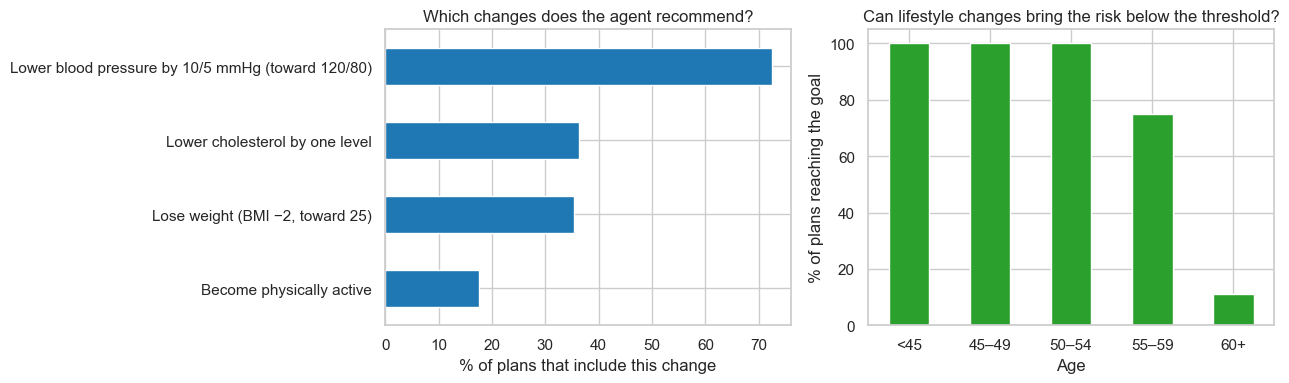

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

usage = plans[list(MEASURABLE_ACTIONS)].mean().rename(lambda a: MEASURABLE_ACTIONS[a]["label"]).sort_values()
usage.mul(100).plot(kind="barh", ax=axes[0], color="tab:blue")
axes[0].set_xlabel("% of plans that include this change")
axes[0].set_title("Which changes does the agent recommend?")

plans["age_group"] = pd.cut(plans["age"], [29, 45, 50, 55, 60, 66], right=False,
                            labels=["<45", "45–49", "50–54", "55–59", "60+"])
plans.groupby("age_group", observed=True)["reached_goal"].mean().mul(100).plot(kind="bar", ax=axes[1], color="tab:green")
axes[1].set_ylabel("% of plans reaching the goal")
axes[1].set_xlabel("Age")
axes[1].set_title("Can lifestyle changes bring the risk below the threshold?")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**How to read these charts:**
- **Left:** blood pressure appears in most plans — it's the strongest lever, agreeing with every earlier part (correlation, Random Forest, GA, LDA).
- **Right:** a sharp age effect. For flagged patients **under 55**, a lifestyle plan reaches the goal **every time**; at **55–59** about **75%** of the time;
  at **60+** only about **1 in 10**. Age is a factor no plan can change, and the model weighs it heavily for older patients.
  For those patients the agent still gives the plan with the largest reduction, and says the goal isn't reachable.

### 9c. Safety: does the agent ever recommend something unhealthy?
By construction, the planner can only use the four healthy changes, so no plan should ever say "start smoking" or "raise blood pressure".
We don't just trust that: we compare each patient's values **before and after** their plan and count any plan that raises blood pressure,
cholesterol or BMI, or makes them less active. We also count how often the knowledge-base rule had to correct the what-if table:

In [16]:
clipped = 0
total = 0
for row, risk in [flagged[i] for i in sample_idx[:300]]:
    steps = agent._max_steps(row)
    for i in range(4):
        if steps[i] == 0:
            continue
        s = [0, 0, 0, 0]; s[i] = steps[i]
        new = agent.full_risk([agent._apply(row, 170, tuple(s))])[0]
        total += 1
        clipped += new > risk                # model said a healthy change INCREASES risk

print(f"Plans recommending an unhealthy change: {unhealthy_plans} of {len(plans)}")
print(f"What-if answers corrected by the knowledge-base rule: {clipped} of {total} ({clipped / total:.1%})")

Plans recommending an unhealthy change: 0 of 1000
What-if answers corrected by the knowledge-base rule: 112 of 619 (18.1%)


- **No plan** recommended an unhealthy change — checked on actual before/after values, not assumed.
- But for **about 1 in 5** what-if answers, the model said a *healthy* change would **raise** risk. That's more than the 1–11% in Step 3, because here
  each change is made **in full** (e.g. cholesterol 3 → 1, or losing 20 kg), pushing patients into value combinations that are rare in the data,
  where the MLP is less reliable. The knowledge-base rule caught every one, and the report says "no measurable benefit in the model" instead of a wrong number.

This is the strongest argument in the project for the neuro-symbolic design: **without the rules, the agent would give wrong advice for a large share of patients.**

In [17]:
Path("results").mkdir(exist_ok=True)
evaluation = {
    "thresholds": {"full": agent.full_threshold, "quick": agent.quick_threshold},
    "test_metrics": pd.DataFrame(rows).set_index("mode").round(4).to_dict(orient="index"),
    "planning": {
        "flagged_test_patients": len(flagged), "sample": len(plans),
        "reached_goal_rate": round(float(plans["reached_goal"].mean()), 4),
        "mean_risk_before": round(float(plans["risk_before"].mean()), 4),
        "mean_risk_after": round(float(plans["risk_after"].mean()), 4),
        "median_cost_goal_plans": float(plans.loc[plans["reached_goal"], "cost"].median()),
        "mean_states_explored": round(float(plans["states_explored"].mean()), 1),
        "action_usage": plans[list(MEASURABLE_ACTIONS)].mean().round(4).to_dict(),
    },
    "safety_check_validation": safety.round(4).reset_index().to_dict(orient="records"),
    "what_if_corrected_by_rules": {"corrected": int(clipped), "total": int(total)},
    "unhealthy_plans": int(unhealthy_plans),
}
with open("results/agent_evaluation.json", "w") as f:
    json.dump(evaluation, f, indent=2)
print("Saved results/agent_evaluation.json")

Saved results/agent_evaluation.json


## Summary

```
                         ┌───────────────────── CardioAgent ─────────────────────┐
 checkup values ──▶ PERCEIVE ──▶ THINK ──────────────────────────────▶ ACT ──▶ report
                    validate     risk: full MLP (Part 1) or            risk level
                    choose mode       quick GA MLP (Part 2)            profile
                                 profile: k-means (Part 3)             factors
                                 what-if + PLAN: uniform-cost search   plan + guideline advice
                                 KNOWLEDGE BASE keeps advice safe      disclaimer
                         └────────────────────────────────────────────────────────┘
```

**What you can now say in your project:**
1. CardioAgent is a **utility-based agent** (PEAS in Step 1): it perceives a record, predicts risk, explains it, and **searches** for the
   lowest-effort lifestyle plan that brings risk below the follow-up threshold.
2. **Safety finding:** the trained models predict that quitting smoking or alcohol *raises* risk — an artefact of the data.
   A **symbolic knowledge base** stops the agent from ever acting on it (**neuro-symbolic** design).
3. **Uniform-cost search** (A\* with h = 0) finds the provably cheapest plan in milliseconds; checked against brute force.
4. The **GA model** (Part 2) enables a quick 3-value screening mode; the **profiles** (Part 3) explain each patient's group.
5. On test patients, both modes catch ≈ 80% of sick patients, and the planner's results are summarised in Step 9.

**Honest limitations:**
- The what-if numbers are **model associations, not proven causal effects** — the agent says so in every report.
- Effort costs are our own judgement, not clinical evidence.
- The model only knows these 11 checkup values; many real risk factors (family history, ECG, medication) are missing.
- It has not been evaluated by doctors or real patients.

**Next: Part 5 (optional) — a small demo app**, and Part 6 — the paper and slides.